### Problem 11 : The Unlearning Audit - one protocol, every method, three kinds of request

⏱️ ~45 min · 🧭 Stage 5 (Proof), rung 7 · 📄 `resources/papers/04-evaluation-and-privacy/2024-hayes-inexact-unlearning-careful-evals.pdf`, `resources/papers/05-llm-unlearning/2024-deeb-roger-do-unlearning-methods-remove-info.pdf`

> 🔗 **Building on Problem 10 :** across Problems 6-10 we built a gold band, a privacy test (U-LiRA), a utility check
> and a cost count, and we learned that self-referential metrics like ZRF can be gamed. But each problem used a
> slightly different table, and every method was tried on its own.

This problem puts it all together as **one audit protocol** : fixed in advance, run the same way on every method, and
written down as an **evidence record** that someone else can check. That is what a regulator, an internal review board,
or the "Unlearning" pillar of the book's RAI Scorecard would actually ask for.

We also add the last test, the one that separates **removal** from **suppression** : the **relearn attack**.

![Audit pipeline](assets/diagrams/09_audit_pipeline.png)

> 🟢 **In plain words :** so far each method has been marking its own homework. An audit is an exam set *before* anyone
> knows the answers, with the same questions for everybody, marked against a reference answer (models that genuinely
> never saw the data). And one of the questions is a trick question : *"if I remind you of half of Carol's digits, how
> quickly do you remember the other half?"*

> 🔴 **For practitioners :** the protocol is (1) **pre-registered** method configurations, (2) N OUT references
> (retrained without D_f) and M IN references (trained with it) **using the same training recipe** as the system under
> audit, (3) five checks : FORGET (gold band), PRIVACY (U-LiRA, Hayes et al. 2024), UTILITY, COST, and RELEARN
> (split-half relearn attack, Deeb & Roger 2024), (4) three request types, because a method that passes one can fail
> another, (5) a machine-readable evidence record.

**TASK :** Run every neural-network method from Problems 6-10 through the same five checks on three requests (a
memorised individual, a whole class, a random 10% of users), find out which methods survive, and save the evidence.

In [1]:
import json, os, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from mul import lab, train, methods, audit, viz
viz.style()

# The protocol, written down BEFORE looking at any result.
# Method settings are each problem's defaults - NOT the best runs from the sweeps in Problems 8-10,
# because picking the best run needs the gold band, which production does not have.
PROTOCOL = dict(
    references=dict(n_out=12, n_in=8),
    gate=dict(k=2.0, min_halfwidth=0.03, utility_tol=0.02, privacy_tol=0.10),
    relearn=dict(target_frac=0.95, max_steps=500, frac_of_reference=0.5),
    methods={
        "fine-tune":       dict(epochs=5, lr=1e-3),
        "gradient ascent": dict(epochs=5, lr=1e-4),
        "NegGrad+":        dict(epochs=5, alpha=0.9, lr=1e-4),
        "SCRUB":           dict(steps=8, max_steps=4, lr=5e-4, forget_batch_size=8, T=1.0),
        "SCRUB+R":         dict(steps=8, max_steps=4, lr=5e-4, forget_batch_size=8, T=1.0),
        "Bad Teacher":     dict(retain_fraction=0.3, epochs=1, lr=1e-3),
    },
    sisa=dict(n_shards=5, n_slices=4, epochs_per_slice=15),
)
print(json.dumps(PROTOCOL["methods"], indent=1))

{
 "fine-tune": {
  "epochs": 5,
  "lr": 0.001
 },
 "gradient ascent": {
  "epochs": 5,
  "lr": 0.0001
 },
 "NegGrad+": {
  "epochs": 5,
  "alpha": 0.9,
  "lr": 0.0001
 },
 "SCRUB": {
  "steps": 8,
  "max_steps": 4,
  "lr": 0.0005,
  "forget_batch_size": 8,
  "T": 1.0
 },
 "SCRUB+R": {
  "steps": 8,
  "max_steps": 4,
  "lr": 0.0005,
  "forget_batch_size": 8,
  "T": 1.0
 },
 "Bad Teacher": {
  "retain_fraction": 0.3,
  "epochs": 1,
  "lr": 0.001
 }
}


#### Step 1 : Train - the original model and the references, for each request

Three requests, each a different *kind* of deletion :

| request | what is deleted | real-world analogue |
|---|---|---|
| **carol** | 40 memorised examples from one person | a GDPR erasure request from one user |
| **class** | every digit 3 | removing one person from a face-recognition model, or one product line |
| **random** | a random 10% of the training set | a bulk retention purge ("delete everything older than 3 years") |

#### Step 2 : Show the issue - and the first surprise

Before any unlearning, let's audit the **original** model, which has *not* forgotten anything, on each request.

In [2]:
# Step 1 + 2: originals, references and the gold band for each request
def references(Lx, fit_fn):
    P = PROTOCOL["references"]
    OUT = [fit_fn(Lx.Xr, Lx.yr, 100 + s) for s in range(P["n_out"])]
    IN = [fit_fn(Lx.X_train, Lx.y_train, 1 + s) for s in range(P["n_in"])]
    return OUT, IN

mono = lambda X, y, seed: train.fit(lab.model_fn, X, y, seed=seed, **lab.FIT)
R = {}
for scen in ["carol", "class", "random"]:
    Lx = lab.make_lab(scen)
    OUT, IN = references(Lx, mono)
    bm, bs = audit.gold_band(OUT, Lx.splits(), in_models=IN, mia=False)
    R[scen] = dict(L=Lx, original=mono(Lx.X_train, Lx.y_train, 0), OUT=OUT, IN=IN, band_mean=bm, band_std=bs)

rows = []
for scen, r in R.items():
    t = audit.audit({"original": r["original"]}, r["L"].splits(), r["OUT"], in_models=r["IN"], mia=False)
    g = audit.gate(t, r["band_mean"], r["band_std"], **PROTOCOL["gate"])
    rows.append(t[["forget_acc", "test_acc", "ulira"]].join(g).assign(request=scen,
                band=f"{r['band_mean'].forget_acc:.1%} ± {2 * r['band_std'].forget_acc:.1%}"))
print(pd.concat(rows).set_index("request").round(3).to_string())

         forget_acc  test_acc  ulira FORGET PRIVACY UTILITY verdict          band
request                                                                          
carol           1.0     0.980  0.950      x       x      ok    FAIL  62.7% ± 9.5%
class           1.0     0.981  1.000      x       x      ok    FAIL   0.0% ± 0.0%
random          1.0     0.980  0.712     ok       x      ok    FAIL  98.2% ± 1.6%


**Stop and notice what just happened.** On the **random** request, the original model, which forgot *nothing*,
**passes the FORGET check**. When you delete a random 10% of a well-generalising model's data, a model retrained
without it gets ~98% on those rows anyway, because they look like everything else. Accuracy simply cannot see the
difference.

Only the PRIVACY check (U-LiRA, which compares each example against IN and OUT models) catches it. This is the central
warning of Hayes et al. (2024) : **evaluations that use random forget sets and accuracy-style metrics will happily
certify a model that did nothing.** A real audit needs per-example privacy tests, and it needs to include *hard*
requests (memorised individuals, whole classes), not just random ones.

#### Step 3 : Untrain - every method, the same way, on every request

In [3]:
# Step 3: run every pre-registered method on every request
def run_methods(r):
    Lx, orig, cfg = r["L"], r["original"], PROTOCOL["methods"]
    runs = {"original": (orig, dict(samples_processed=0)),
            "retrain": methods.retrain(lab.model_fn, Lx.Xr, Lx.yr, seed=999, **lab.FIT),
            "fine-tune": methods.finetune(orig, Lx.Xr, Lx.yr, **cfg["fine-tune"]),
            "gradient ascent": methods.gradient_ascent(orig, Lx.Xf, Lx.yf, **cfg["gradient ascent"]),
            "NegGrad+": methods.neggrad_plus(orig, Lx.Xr, Lx.yr, Lx.Xf, Lx.yf, **cfg["NegGrad+"]),
            "SCRUB": methods.scrub(orig, Lx.Xr, Lx.yr, Lx.Xf, **cfg["SCRUB"]),
            "SCRUB+R": methods.scrub_rewind(orig, Lx.Xr, Lx.yr, Lx.Xf, Lx.yf, Lx.X_like_forget, Lx.y_like_forget, **cfg["SCRUB+R"]),
            "Bad Teacher": methods.bad_teacher(orig, lab.model_fn, Lx.Xr, Lx.Xf, **cfg["Bad Teacher"])}
    return {k: v[0] for k, v in runs.items()}, {k: v[1]["samples_processed"] for k, v in runs.items()}

def full_audit(models, costs, r):
    """The five checks of the protocol on a dict of models. Returns one table."""
    Lx, ref_cost = r["L"], lab.FIT["epochs"] * len(r["L"].Xr)
    t = audit.audit(models, Lx.splits(), r["OUT"], costs=costs, in_models=r["IN"], mia=False)
    t = t.join(audit.gate(t, r["band_mean"], r["band_std"], cost_ref=ref_cost, **PROTOCOL["gate"]))
    rl, r["ref_relearn"] = audit.relearn_test(models, Lx.Xf, Lx.yf, r["OUT"], r["original"], **PROTOCOL["relearn"])
    t = t.join(rl)
    t["cost_%"] = 100 * t["cost"] / ref_cost
    t["verdict"] = np.where((t.verdict == "PASS") & t.RELEARN.isin(["ok", "n/a"]), "PASS", "FAIL")
    return t

for scen, r in R.items():
    models, costs = run_methods(r)
    r["table"] = full_audit(models, costs, r)
cols = ["forget_acc", "test_acc", "ulira", "relearn_steps", "cost_%", "FORGET", "PRIVACY", "UTILITY", "COST", "RELEARN", "verdict"]
for scen, r in R.items():
    print(f"=== {scen}   (relearn steps for the 12 retrained references: median {np.median(r['ref_relearn']):.0f})")
    print(r["table"][cols].round(3).to_string()); print()

=== carol   (relearn steps for the 12 retrained references: median 500)
                 forget_acc  test_acc  ulira  relearn_steps   cost_% FORGET PRIVACY UTILITY COST RELEARN verdict
method                                                                                                          
original              1.000     0.980  0.950              0    0.000      x       x      ok   ok       x    FAIL
retrain               0.625     0.980  0.075            500  100.000     ok      ok      ok  ref      ok    PASS
fine-tune             1.000     0.981  0.875              0    8.333      x       x      ok   ok       x    FAIL
gradient ascent       1.000     0.983  0.600              0    0.274      x       x      ok   ok       x    FAIL
NegGrad+              0.100     0.846  0.000             27    8.607      x      ok       x   ok       x    FAIL
SCRUB                 0.825     0.978  0.275             18   13.552      x       x      ok   ok       x    FAIL
SCRUB+R               0.

#### Step 4 : Show the result - the verdict map

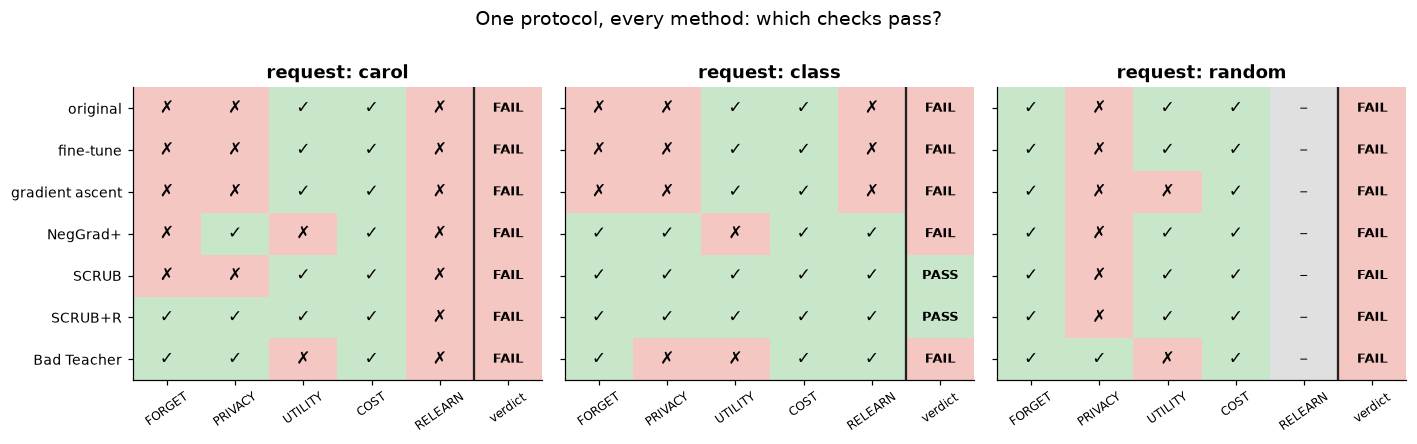

In [4]:
# Step 4: one picture - which check does each method fail, on which request?
checks = ["FORGET", "PRIVACY", "UTILITY", "COST", "RELEARN", "verdict"]
names = [m for m in R["carol"]["table"].index if m != "retrain"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, (scen, r) in zip(axes, R.items()):
    t = r["table"].loc[names, checks].replace({"ok": 1.0, "ref": 1.0, "PASS": 1.0, "x": 0.0, "FAIL": 0.0, "n/a": 0.5}).astype(float)
    ax.imshow(t.values, cmap=ListedColormap(["#f4c7c3", "#e0e0e0", "#c8e6c9"]), vmin=0, vmax=1, aspect="auto")
    for i in range(len(names)):
        for j in range(len(checks)):
            mark = {1.0: "✓", 0.5: "–", 0.0: "✗"}[t.values[i, j]] if j < 5 else ("PASS" if t.values[i, j] else "FAIL")
            ax.text(j, i, mark, ha="center", va="center", fontsize=11 if j < 5 else 8.5, fontweight="bold" if j == 5 else None)
    ax.axvline(4.5, color=viz.INK, lw=1.5)
    ax.set_xticks(range(len(checks))); ax.set_xticklabels(checks, rotation=35, fontsize=8)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=9); ax.grid(False)
    ax.set_title(f"request: {scen}")
plt.suptitle("One protocol, every method: which checks pass?", y=1.0); plt.tight_layout(); plt.show()

Read the map row by row.

- **fine-tune** and **gradient ascent** at their defaults barely move the model. They fail the hard requests the same
  way the original does.
- **NegGrad+** at its default over-forgets Carol and costs utility on both hard requests.
- **SCRUB** handles the class request, and **SCRUB+R** passes the four checks we had until now on Carol *and* the class.
  On the old four-check table it would look like the winner.
- **Bad Teacher** fails PRIVACY on the class request (Problem 10) and UTILITY on all three at its default.
- On the **random** request nothing passes. The retrained references get flagged by U-LiRA on about a third of the
  rows (some rows simply look like members), and most methods stay at 50-73%, close to the original's 71%. Bad
  Teacher is the exception on privacy, but it pays for it in utility. RELEARN shows "n/a" here : the retrained models
  already get those rows right without any extra training, so the attack has nothing to measure.

Now look at the RELEARN column for Carol.

#### Step 5 : Prove it - removed, or just hidden ?

The relearn attack (Lynch et al. 2024; Deeb & Roger 2024) : fine-tune the model on **the first half of Carol's digits**
and count the steps until it is right on **the other half**, digits it was never re-shown, as often as the original
was. A model that never saw Carol has to genuinely learn her style from 20 examples, which is slow. A model in which
Carol's influence was only *pushed aside* gets the other half back almost for free.

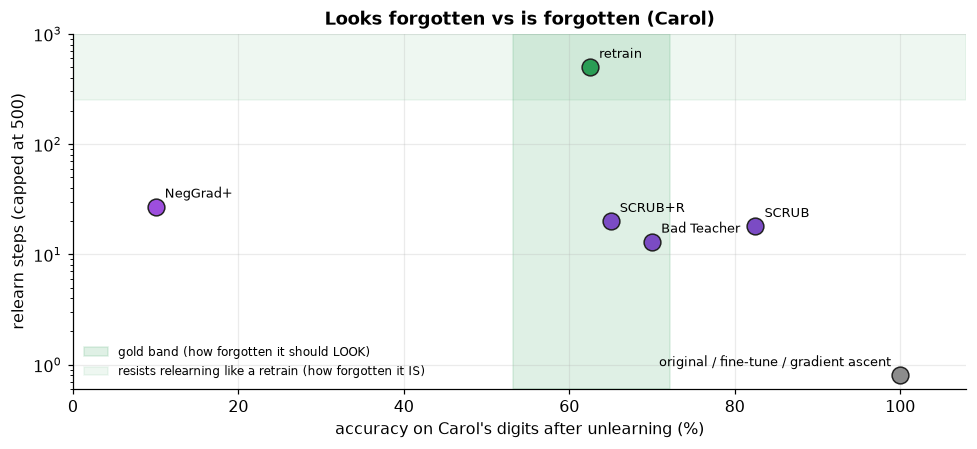

relearn steps, retrained references: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
method
original             0
retrain            500
fine-tune            0
gradient ascent      0
NegGrad+            27
SCRUB               18
SCRUB+R             20
Bad Teacher         13


In [5]:
# Step 5a: the relearn attack, close up (Carol)
r = R["carol"]
t = r["table"]
fig, ax = plt.subplots(figsize=(9, 4.2))
lo = r["band_mean"].forget_acc - 2 * r["band_std"].forget_acc
hi = r["band_mean"].forget_acc + 2 * r["band_std"].forget_acc
ax.axvspan(100 * lo, 100 * hi, color=viz.RETRAIN, alpha=0.15, label="gold band (how forgotten it should LOOK)")
bar = PROTOCOL["relearn"]["frac_of_reference"] * np.median(r["ref_relearn"])
ax.axhspan(bar, 1000, color=viz.RETRAIN, alpha=0.08, label="resists relearning like a retrain (how forgotten it IS)")
pts = t.assign(x=100 * t.forget_acc, y=t.relearn_steps.clip(lower=0.8)).reset_index()
for (x, y), grp in pts.groupby(["x", "y"]):                      # methods at the same spot share one label
    ax.scatter(x, y, s=120, color=viz.color_for(grp.method.iloc[0]), edgecolors=viz.INK, zorder=3)
    ax.annotate(" / ".join(grp.method), (x, y), textcoords="offset points", xytext=(-6 if x > 90 else 6, 6),
                ha="right" if x > 90 else "left", fontsize=8.5)
ax.set_yscale("log"); ax.set_ylim(0.6, 1000); ax.set_xlim(0, 108)
ax.set_xlabel("accuracy on Carol's digits after unlearning (%)")
ax.set_ylabel(f"relearn steps (capped at {PROTOCOL['relearn']['max_steps']})")
ax.set_title("Looks forgotten vs is forgotten (Carol)"); ax.legend(fontsize=8, loc="lower left"); plt.tight_layout(); plt.show()
print("relearn steps, retrained references:", r["ref_relearn"])
print(t["relearn_steps"].to_string())

**Read that again.** SCRUB+R sits right inside the gold band : Carol's accuracy looks exactly like a model that never
met her, and U-LiRA agrees. But show it 20 of her digits for a few steps and it is right about the *other* 20, the
ones it was never re-shown, about as often as the original was. The retrained models cannot do that within the full
step budget, because for them there is nothing to recall.

That is the difference between **removal** and **suppression**, and it is the single most important idea for LLM
unlearning (Problem 16) : approximate methods mostly change *what the model says* without removing *what the model
knows*. Only the exact methods (retrain, SISA) and the classical exact updates of Problems 1-3 pass RELEARN by
construction.

The class request gives a useful counterpoint. There, retrained references relearn 3s in under 10 steps too, because
"what a 3 looks like" is general knowledge the rest of the model already has (curves, strokes). Relearning is fast for
everyone, so the test cannot separate the methods. **The relearn attack measures memorised, specific information,
which is exactly what privacy law cares about.**

#### Step 5b : The exact method, audited with its own recipe

SISA (Problem 7) is exact by construction, so it should pass everything, **as long as its references are trained with
the SISA recipe** (the recipe trap from Problem 7). We audit it with 12 + 8 SISA references per request.

In [6]:
# Step 5b: SISA through the same protocol, against SISA-recipe references
def sisa_fit(X, y, seed):
    m = methods.SISA(lab.model_fn, seed=seed, **PROTOCOL["sisa"]); m.fit(X, y); return m

sisa_rows = []
for scen, r in R.items():
    Lx = r["L"]
    OUT_s, IN_s = references(Lx, sisa_fit)
    bm_s, bs_s = audit.gold_band(OUT_s, Lx.splits(), in_models=IN_s, mia=False)
    system = sisa_fit(Lx.X_train, Lx.y_train, 0)
    system, info = system.unlearn(Lx.forget_idx)
    rs = dict(L=Lx, OUT=OUT_s, IN=IN_s, band_mean=bm_s, band_std=bs_s, original=sisa_fit(Lx.X_train, Lx.y_train, 0))
    t = full_audit({"SISA (unlearned)": system}, {"SISA (unlearned)": info["samples_processed"]}, rs)
    sisa_rows.append(t[cols].assign(request=scen))
    r["table"] = pd.concat([r["table"], t])
print(pd.concat(sisa_rows).set_index("request").round(3).to_string())

         forget_acc  test_acc  ulira  relearn_steps  cost_% FORGET PRIVACY UTILITY COST RELEARN verdict
request                                                                                                
carol         0.525     0.980  0.175            NaN  61.360      x      ok      ok   ok     n/a    FAIL
class         0.000     0.979  0.000            NaN  62.489     ok      ok      ok   ok     n/a    PASS
random        0.960     0.976  0.464            NaN  62.213     ok      ok      ok   ok     n/a    PASS


SISA passes PRIVACY and UTILITY on all three requests and passes the class and random requests outright. RELEARN shows
"n/a" : the attack fine-tunes one network, and SISA is an ensemble of five. It does not need the test, though. After
unlearning, the system is **bit-for-bit identical** to a SISA system trained without D_f (Problem 7), so any attack,
relearning included, behaves on it exactly as on that reference.

**But look at Carol : the exact method fails FORGET.** It gets 21 of her 40 digits right (52.5%), and the band from 12
SISA references starts at about 52.6%. One digit. Nothing is wrong with SISA : this *is* a model that never saw Carol.
A band of ±2 standard deviations, estimated from 12 references, on a 40-example forget set (2.5-point steps), will
**sometimes reject a perfectly good model**. That is a false alarm, and every statistical test has a false-alarm rate.

Two lessons. First, a FAIL from an audit is a reason to **investigate**, not an automatic verdict; here the
investigation ends quickly, because SISA's exactness is a property of the *process* and can be checked from its logs.
Second, the width of the band is a policy choice (more references, a wider k, a larger forget set), and Problem 17
gives it an owner. Its weak spot is COST : with a random partition, one request touches most shards (Problem 7), so
it costs a large fraction of a retrain. The cost depends on how the data was partitioned, not on how hard the request
is. With a **user-aware** partition, Carol's request costs ~5% (Problem 7).

#### Step 5c : Write it down - the evidence record

An audit nobody can re-check is an opinion. The protocol, the reference band, every number and every verdict go into
a machine-readable record. Problem 17 turns these into the certificate a Data Protection Officer signs, and the slide
deck uses the same files.

In [7]:
# Step 5c: one JSON evidence record per request, in results/
os.makedirs("results", exist_ok=True)
for scen, r in R.items():
    record = dict(
        request=scen, dataset="sklearn digits (8x8)", forget_rows=int(len(r["L"].forget_idx)),
        model=dict(architecture="MLP 64-256-256-10", parameters=lab.model_fn().n_params(), recipe=lab.FIT),
        protocol=PROTOCOL,
        gold_band={k: dict(mean=float(r["band_mean"][k]), std=float(r["band_std"][k])) for k in ["forget_acc", "test_acc", "ulira"]},
        reference_relearn_steps=[int(s) for s in r["ref_relearn"]],
        results=json.loads(r["table"][cols].to_json(orient="index")),
        environment=dict(python=platform.python_version(), numpy=np.__version__),
    )
    with open(f"results/audit_{scen}.json", "w") as f:
        json.dump(record, f, indent=1)
print(json.dumps(json.load(open("results/audit_carol.json"))["results"]["SCRUB+R"], indent=1))
print(sorted(os.listdir("results")))

{
 "forget_acc": 0.65,
 "test_acc": 0.9796296296,
 "ulira": 0.125,
 "relearn_steps": 20.0,
 "cost_%": 13.5524513832,
 "FORGET": "ok",
 "PRIVACY": "ok",
 "UTILITY": "ok",
 "COST": "ok",
 "RELEARN": "x",
 "verdict": "FAIL"
}
['audit_carol.json', 'audit_class.json', 'audit_random.json', 'certificate_UC-2026-0101.json']


#### What an audit can and cannot prove

> 🔴 **For practitioners :** Thudi, Jia, Shumailov & Papernot (2022, `resources/papers/04-evaluation-and-privacy/2021-thudi-auditable-definitions.pdf`)
> show that an auditor looking only at the final weights can be **fooled** : the same weights can be reached with or
> without a given example ("forging"). So a black-box audit like this one gives **evidence, not proof**. It can show
> that a method *failed*. A pass only means no test we ran could tell the difference. Real guarantees come from the
> **process** : retraining, SISA with logged partitions, or the exact classical updates. That is why Problem 17's
> playbook prefers exact methods by design and treats approximate methods plus an audit as the fallback.

----
#### OUTCOME :

| method (default settings) | carol | class | random | what fails |
|---|---|---|---|---|
| fine-tune | ❌ | ❌ | ❌ | does not forget, fails privacy |
| gradient ascent | ❌ | ❌ | ❌ | does not forget at a safe learning rate |
| NegGrad+ | ❌ | ❌ | ❌ | over-forgets, costs utility |
| SCRUB | ❌ | ✅ | ❌ | relapses on Carol, privacy on random |
| SCRUB+R | ❌ (RELEARN) | ✅ | ❌ | **passes 4 checks on Carol but relearns in a few steps** |
| Bad Teacher | ❌ | ❌ | ❌ | utility, and privacy on the class request |
| **SISA (own references)** | ⚠️ false alarm | ✅ | ✅ | exact by construction; FORGET misses by one digit on Carol; COST depends on the partition |

#### Key Takeaways :

- **Pre-register** the method settings. Tuning against the gold band is not possible in production, so it must not
  happen in an audit either.
- References must use the **same recipe** as the system under audit (Problem 7).
- **Random forget sets fool accuracy-based audits** : the original model passes FORGET. Use per-example privacy tests
  (U-LiRA) and hard requests.
- The **relearn attack** separates *removed* from *suppressed*. The approximate method that looked best (SCRUB+R) is
  suppressed on Carol.
- Only **exact** methods are truly safe - yet even SISA can trip a statistical check. A black-box audit is evidence,
  not proof (Thudi et al.) : it has false alarms *and* blind spots, so exact-by-process beats passed-the-audit.
- Write the result down as a **machine-readable evidence record**.

#### TASK :
1. Add the best-tuned configuration from each of the Problem 8-10 sweeps to `PROTOCOL["methods"]` and re-run. Which
   ones now pass on Carol? Do any of them pass RELEARN? What does that tell you about tuning vs removal?
2. Run SISA with the **user-aware** partition from Problem 7 for the carol request. Its references must use the same
   partition rule. How much does COST improve?
3. The relearn attack here fine-tunes with lr=1e-3. A stronger attacker uses more steps or a higher learning rate.
   Re-run with `lr=3e-3` (pass it via `PROTOCOL["relearn"]`) and see whether the retrained references still resist.
4. Change `privacy_tol` from 0.10 to 0.05. Which verdicts flip? Who should own that number in a company : the ML team,
   legal, or the DPO? (Problem 17.)

#### ❓ Open question → Problem 12
Everything so far used 8×8 digits and an invented "Carol". **What happens on real personal data, when a real person
invokes their right to be forgotten, and when the people who ask to be deleted are not a random sample of the
population?** That is Problem 12, on the Adult census dataset.